# Moment reproduction per statistic

For each statistic $k$, with $m_k$ = mean on the data x1 ($n$ windows) and $\hat m_k$ = mean on the model samples ($n_s$):

- **offset** $=\sqrt{e_k} = |m_k-\hat m_k| / \mathrm{std}_{data,k}$: how far the model's mean is, in standard deviations of the data (not a % of the mean). Reading: < 0.05 very good, 0.05–0.2 small shift, 0.2–0.5 clear shift, > 0.5 big miss.
- **noise** $=\sqrt{(s^2_{data}/n + s^2_{model}/n_s)}/\mathrm{std}_{data}$: the offset expected from finite samples alone (≈ 0.014 at $n=n_s=10^4$ for well-behaved statistics, much larger for heavy-tailed ones).
- **Verdict** of each statistic (heatmap):
  - **grey = matched**: offset ≤ 2 × noise, and 2 × noise < 0.05, so the measurement is sharp enough to call it a match;
  - **hatched = can't tell**: offset ≤ 2 × noise, but the noise is too large to judge;
  - **colour = miss**: the offset, fixed log scale 0.01 to 1.
- **rel_mean** $=(\hat m_k-m_k)/|m_k|$: percentage error, in the table only, where the mean is clearly away from 0.

Imposed (dot) = the run's own potentials (config.json + fitted_potentials/, never refitted). Extra = chosen in the ⚠ cell. First seed of each label. Run on Jean Zay. Models are grouped by dataset: rows of one heatmap share M, J, Q. Thresholds: `NOISE_K`, `RESOLVED_MAX`, `REL_MEAN_MIN`, `OFFSET_RANGE` at the top of `moment_reproduction.py`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / 'moment_reproduction'))
import numpy as np
from moment_reproduction import load_model, compute_moment_reproduction, plot_summary, plot_strip, DEVICE
%matplotlib inline

In [2]:
# ── MODELS ── group -> {row name: (results root, --label of the run)}. Every statistic a model imposes
# is always checked (loaded with its saved fit, never refitted).
# Turbulence rows: mass_final = M3 + Scat4; M3 = unconstrained windows; A = windows >= step noise;
# B = A + mass of every window. GGD columns are aligned by (channel, window) label, but M3/mass_final
# windows differ from A/B windows: same label != same window across those two pairs.
GROUPS = {
    'turbulence (M=256, J=8, Q=3)': {
        'full (Scat4)':      (ROOT / 'turbulence', 'turbulence_ggd_mass_final'),
        #'M3':                (ROOT / 'turbulence', 'turbulence_nested_M3'),
        #'A (bicw)':          (ROOT / 'turbulence', 'turbulence_nested_M3_bicw'),
        'B (bicw_allmass)':  (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass'),
        'C (bicw_rich)':     (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_rich'),
        'B + Scat4':         (ROOT / 'turbulence', 'turbulence_nested_M3_bicw_allmass_scat4'),
    },
}

## ⚠ CHOOSE THE EXTRA STATISTICS HERE

The **imposed** statistics of each model are always checked, with no choice needed. `EXTRA` lists the **additional, non-imposed** families evaluated on every model of a group. A family that a model imposes stays imposed for that model, using its own fit (matched by family name). The same extra family is a *test* for the models that don't impose it.

- Scattering / L_p extras: no fit, same definition for every model.
- `Scalar_*` extras (GGD): windows **fitted once on the data x1** (final-model settings, `EXTRA_GGD` in `moment_reproduction.py`), saved in `moment_reproduction/cache/`, and reused for every model with the same x1.
- Not caught automatically: two families with different names computing the same numbers. For example, with Q=1 (jets) `Scalar_psi` runs on the same bank as `Scalar_morlet`.

In [3]:
# ── EXTRA (non-imposed) STATISTICS ── edit this list only; one per line, with why it is here.
EXTRA = [
    'L_6',                                      # 6th-order marginal moment (imposed by most turbulence models)
    'Scattering_First_Order',                   # E|W x| per channel
    'Scattering_Second_Order',                  # E|W |W x||: scale-to-scale envelope
    'Scattering_Third_Order_Real',              # cross-scale phase (Q=3 bank, as the code does)
    'Scattering_Third_Order_Imag',
    'Scattering_Fourth_Order_Mod2_Real_Q1',     # the Scat4 mass_final IMPOSES: test for M3 / A / B
    'Scattering_Fourth_Order_Mod2_Imag_Q1',
    'Scalar_morlet_gaussianK',                  # marginals Q=1 bank (imposed by all turbulence models)
    'Scalar_psi_gaussianK',                     # marginals Q=3 bank (imposed by all turbulence models)
    'Scalar_morlet_gaussianK_imag',             # marginals of the imaginary parts: fitted here (not imposed)
    'Scalar_psi_gaussianK_imag',
    'Scalar_Q4_gaussianK',                      # marginals, Q=4 bank at the run's J=8
    'Scalar_Q5_gaussianK',                      # marginals, Q=5 bank
]
print(f'device: {DEVICE}')

device: cuda


In [4]:
import time
results, excluded = {}, {}
for group, models in GROUPS.items():
    results[group], shapes = {}, set()
    for name, (root, label) in models.items():
        t0 = time.time()
        cfg, pots, x1, xs = load_model(label, root)
        shapes.add((cfg['M'], cfg['J'], cfg['Q']))
        extra = [f for f in EXTRA if f not in pots]
        print(f'\n{name}: {cfg["config_name"]}  n={len(x1)} n_s={len(xs)}\n  imposed: {list(pots)}\n  extra:   {extra}')
        results[group][name], excluded[name] = compute_moment_reproduction(pots, x1, xs, EXTRA, cfg)
        print(f'  excluded (zero variance on data): {list(excluded[name].label)}  ({time.time() - t0:.0f} s)')
    assert len(shapes) == 1, f'{group}: models with different (M, J, Q) {shapes}: split the group'

[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)

full (Scat4): turbulencesynth_M256_J8_Q3_sigma3.5_nt55000_n1_10000_lam0.0_thomas_nsub1_moment_f64_dedupfilt1e-08_seed_900_terms9296e719_turbulence_ggd_mass_final_20261022_1840  n=10000 n_s=10000
  imposed: ['L_6', 'Scalar_psi_gaussianK', 'Scalar_morlet_gaussianK', 'Scattering_Fourth_Order_Mod2_Real_Q1', 'Scattering_Fourth_Order_Mod2_Imag_Q1']
  extra:   ['Scattering_First_Order', 'Scattering_Second_Order', 'Scattering_Third_Order_Real', 'Scattering_Third_Order_Imag', 'Scalar_morlet_gaussianK_imag', 'Scalar_psi_gaussianK_imag', 'Scalar_Q4_gaussianK', 'Scalar_Q5_gaussianK']
[extra] Scalar_morlet_gaussianK_imag: windows loaded from Scalar_morlet_gaussianK_imag_2a89d670b918e438.pt
[extra] Scalar_psi_gaussianK_imag: windows loaded from Scalar_psi_gaussianK_imag_5498d85748d6ee39.pt
[extra] Q=4 bank at J=8 (M=256): dropped empty wavelets [31] of 32
schedule two_phase: 5

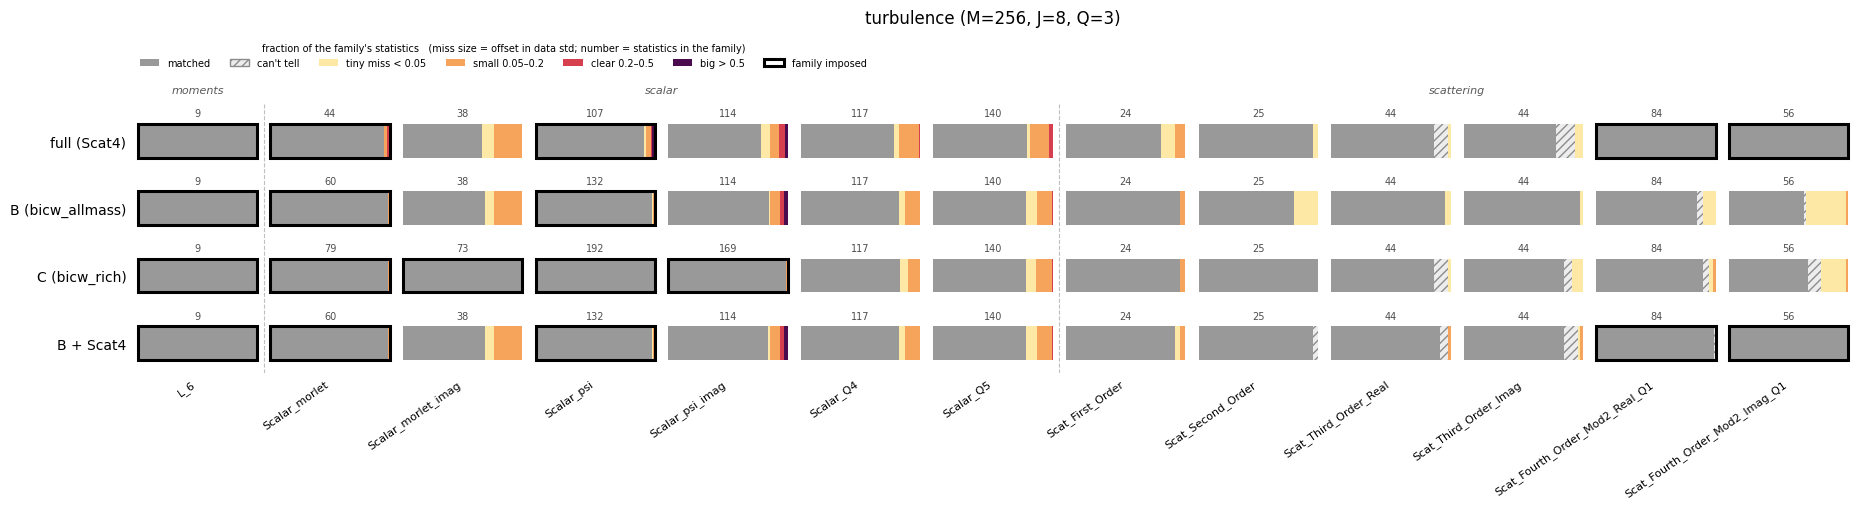

In [5]:
# Overview: one cell per (model, family) = fraction of that family's statistics matched / can't tell /
# missed by size. Thick frame = family imposed by the model. Details per statistic: strip plots below.
for group, res in results.items():
    plot_summary(res, title=group)

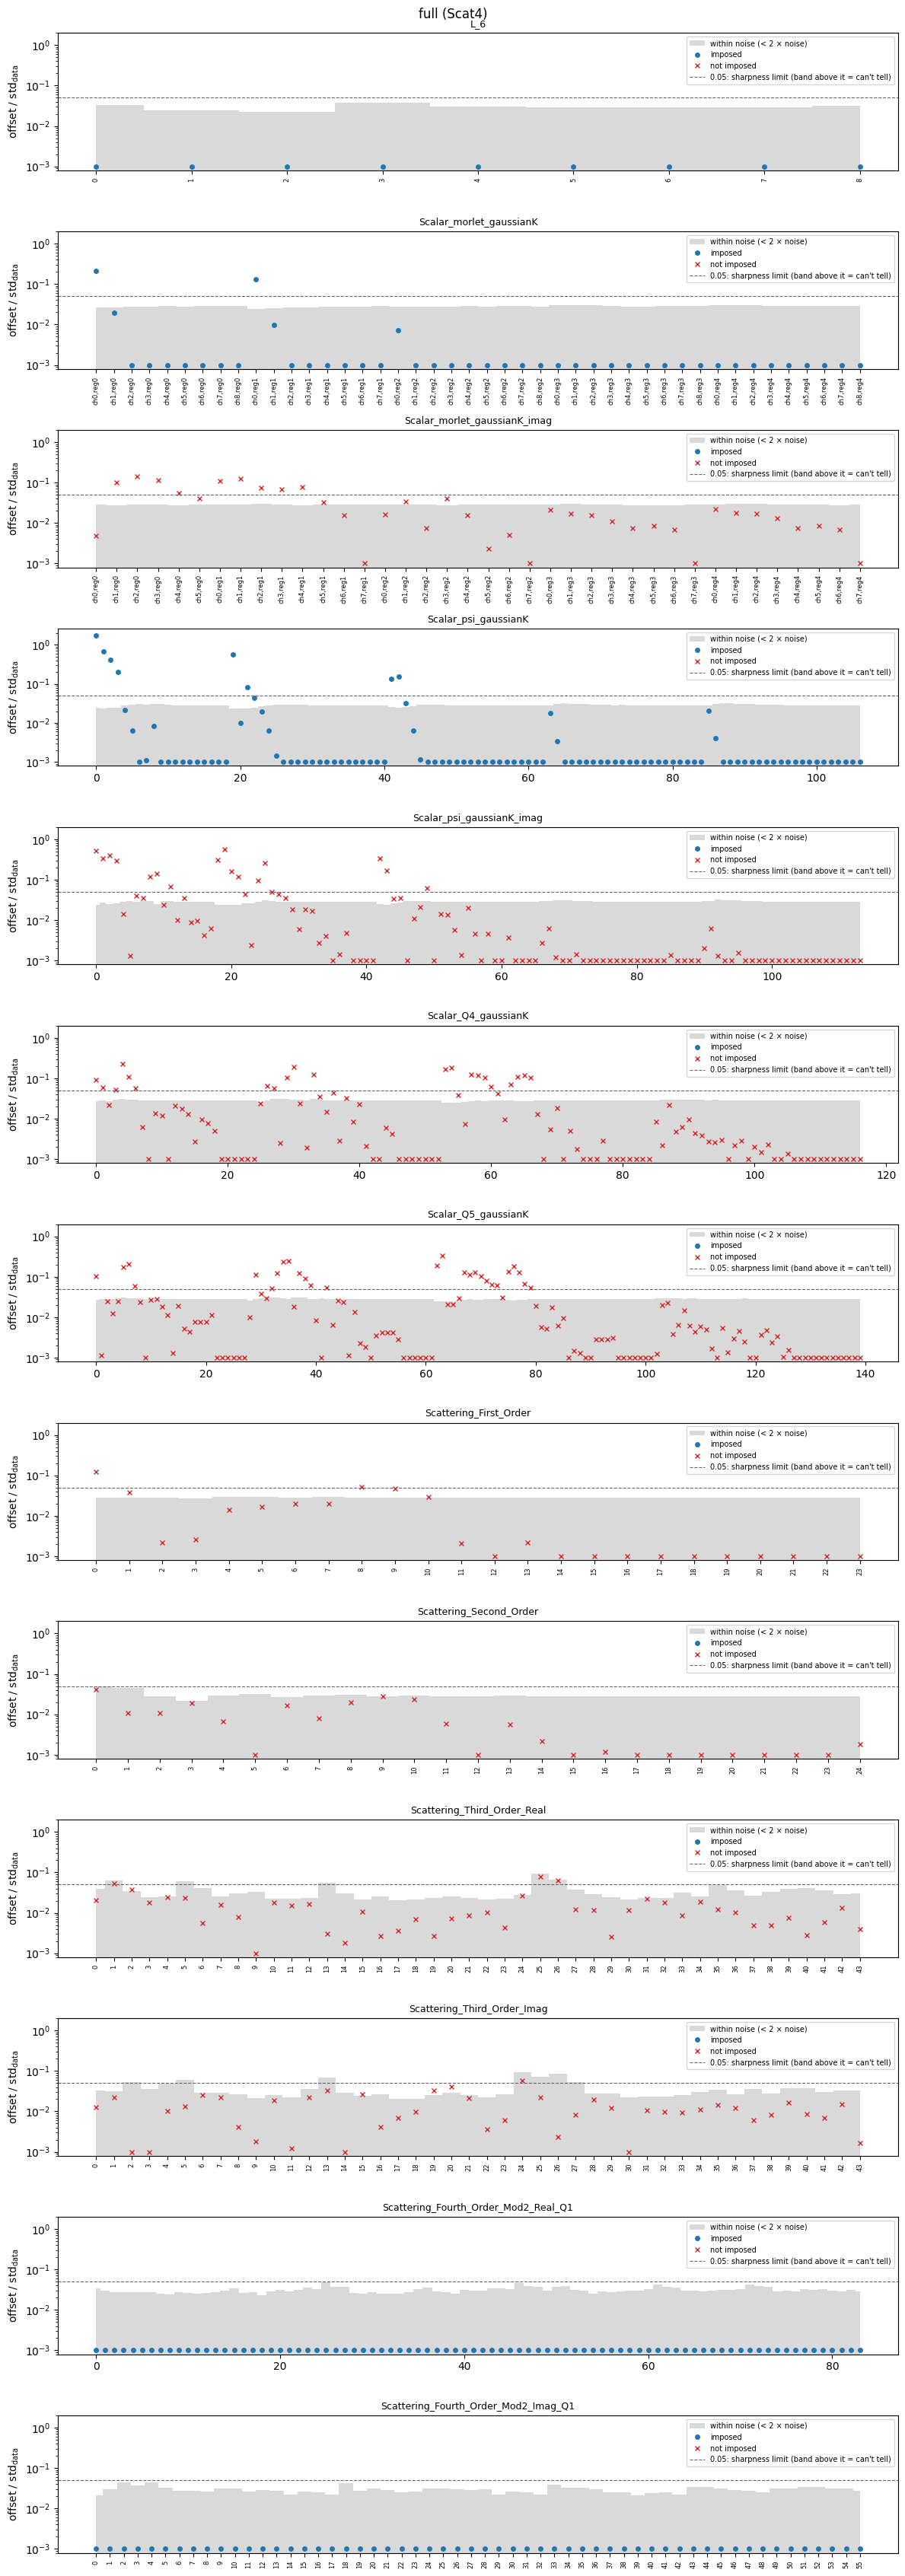

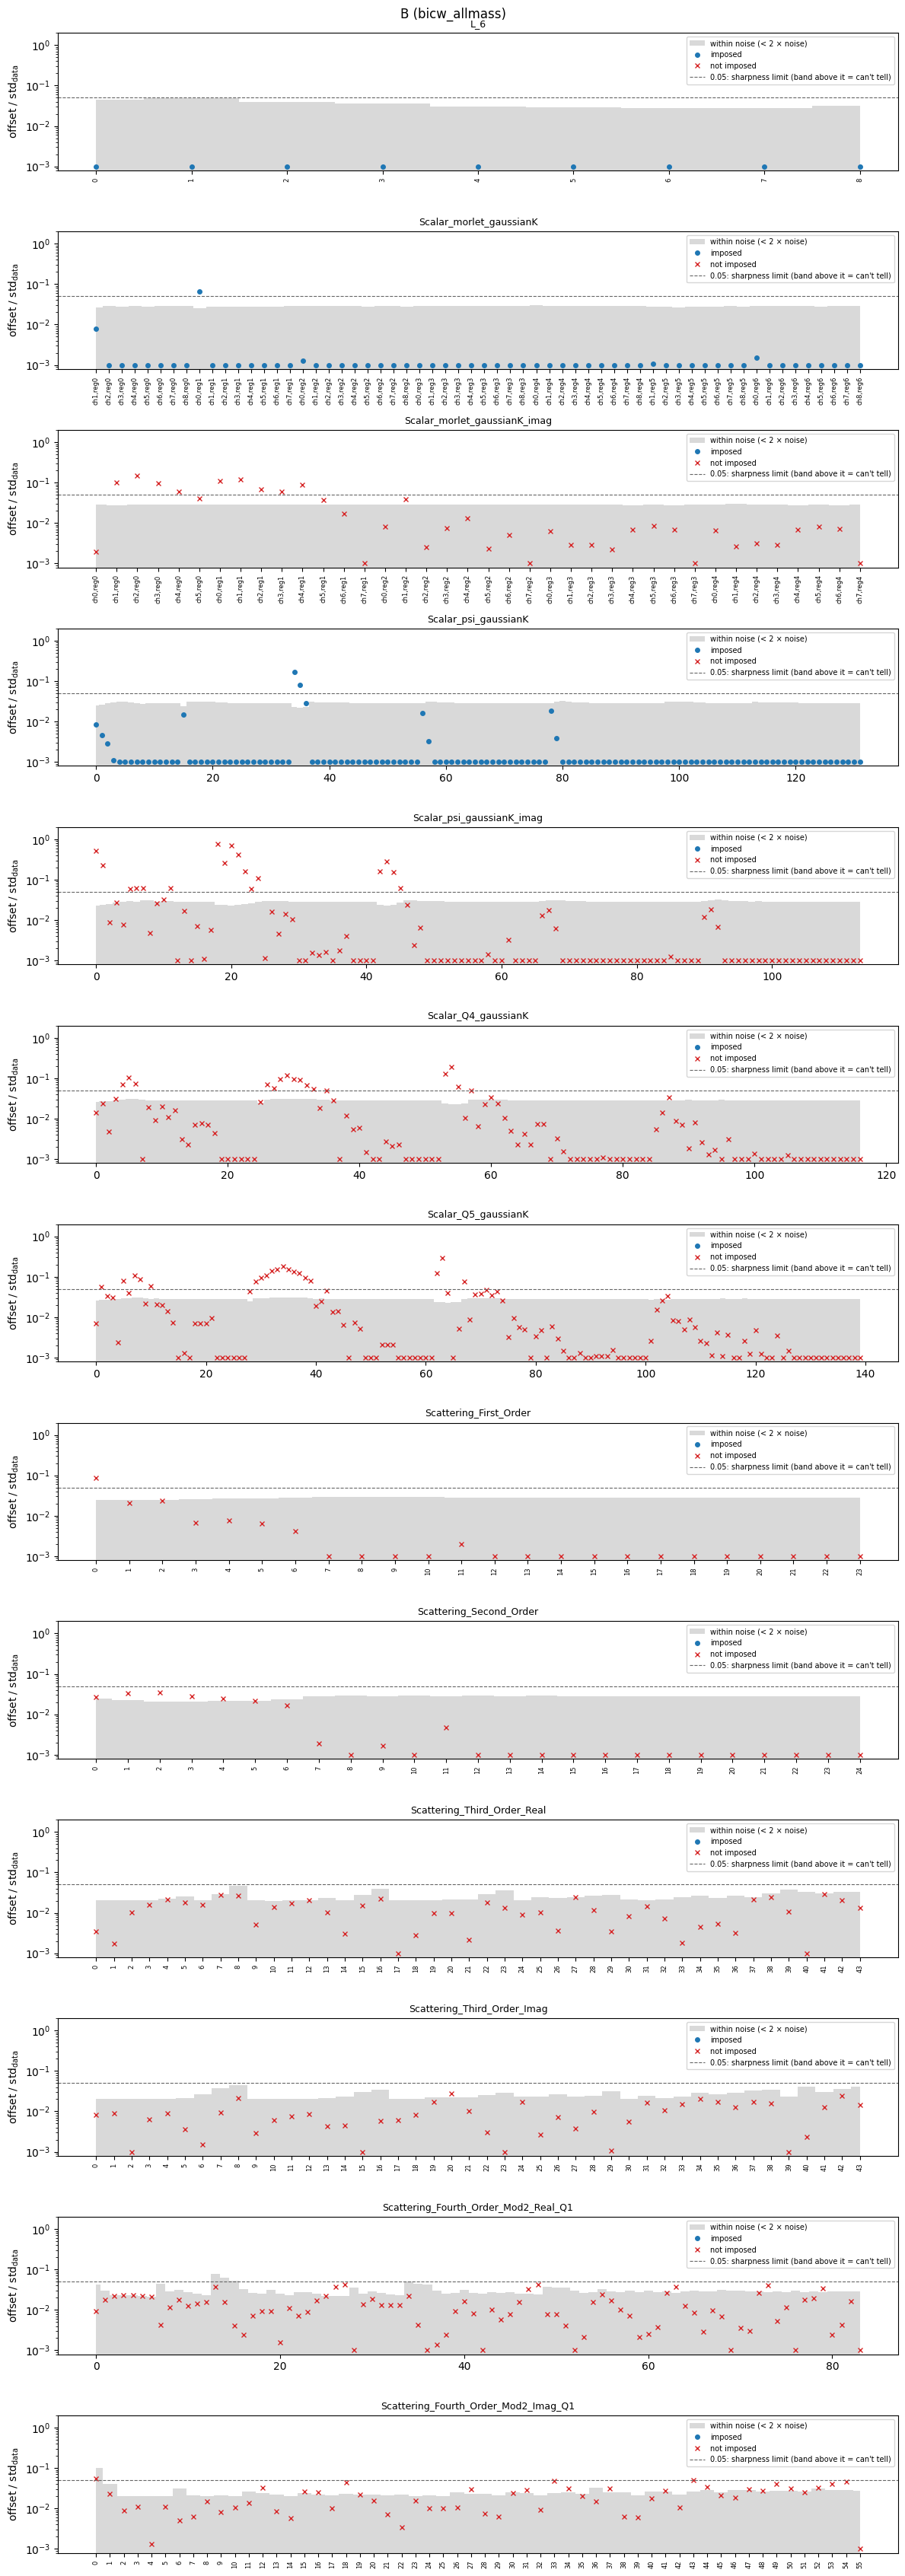

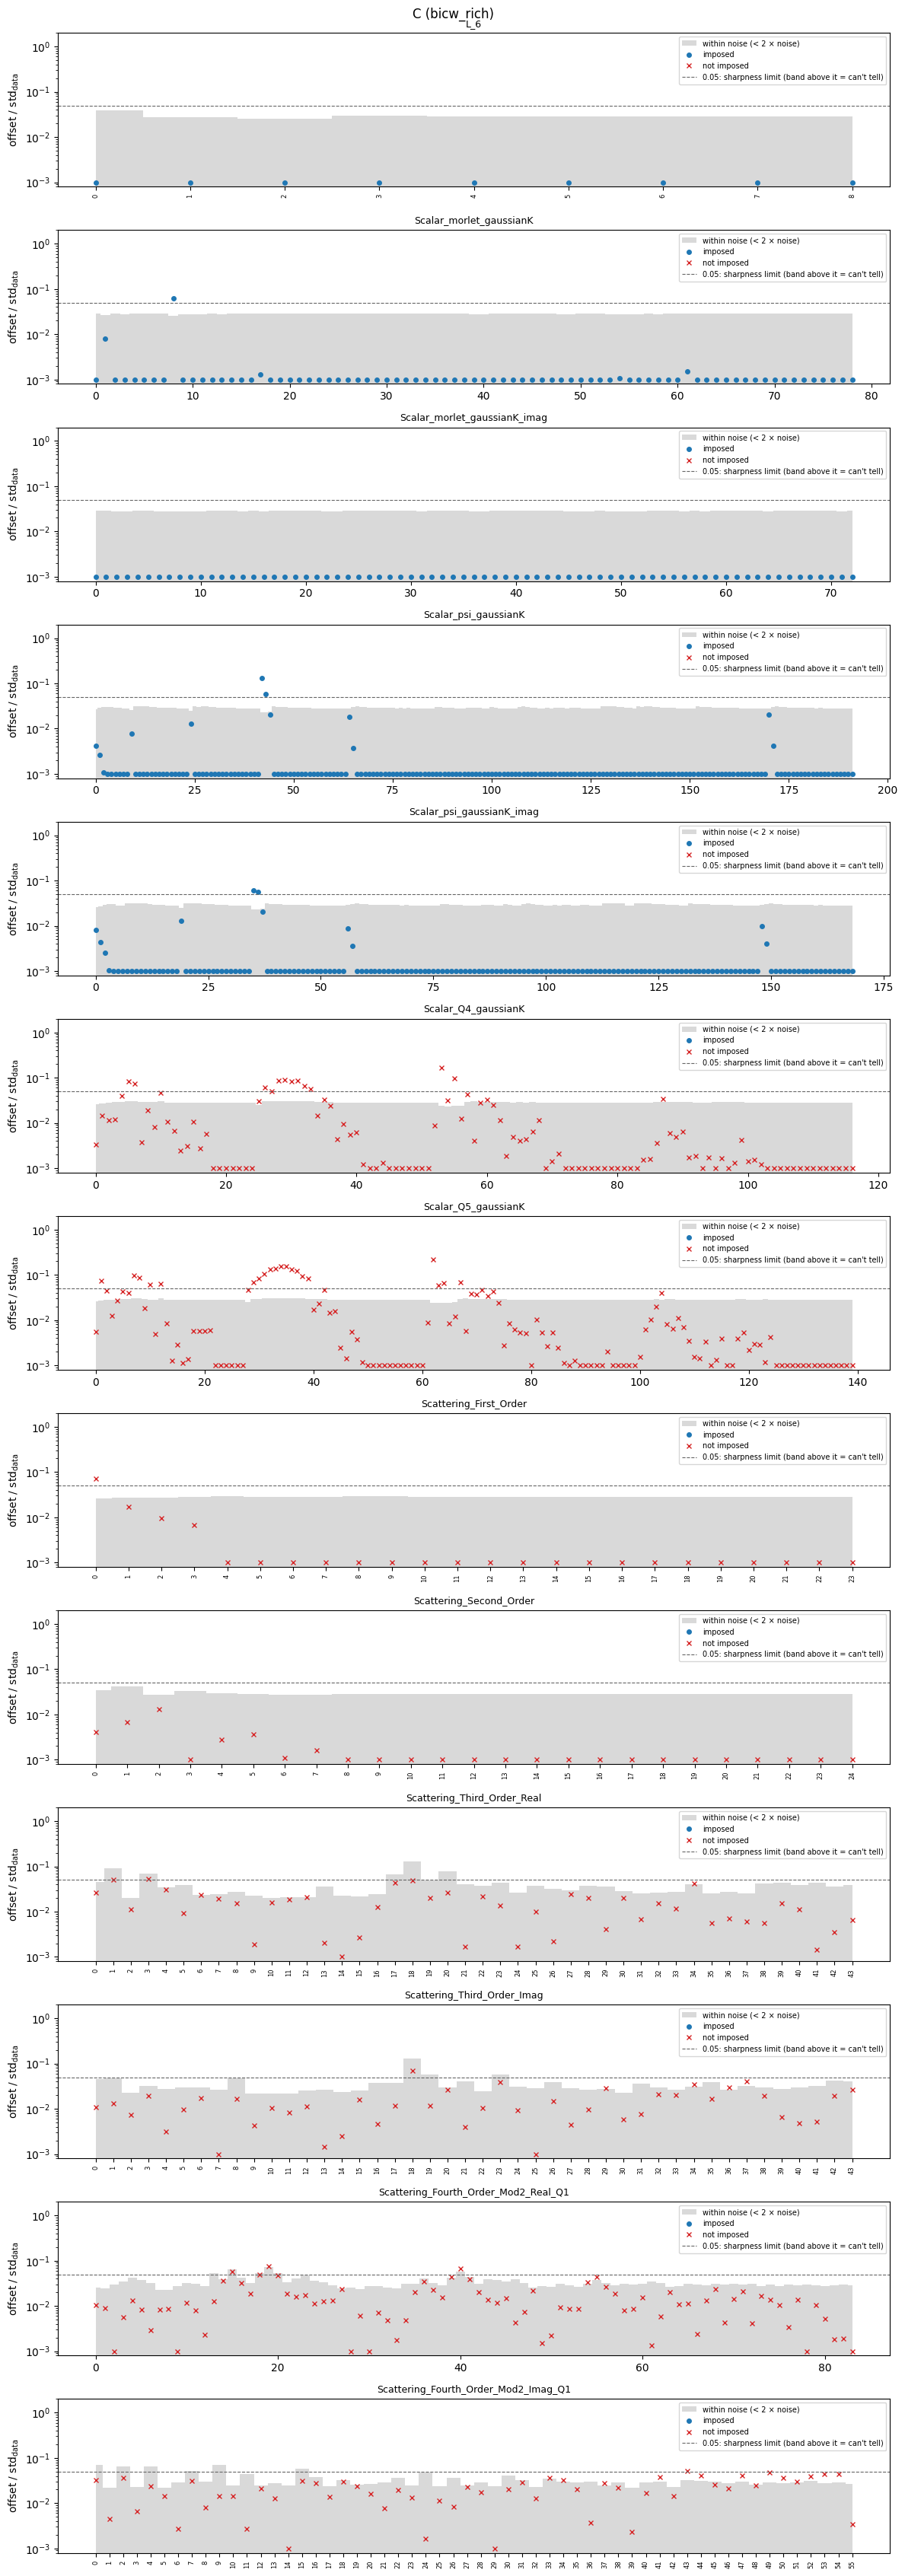

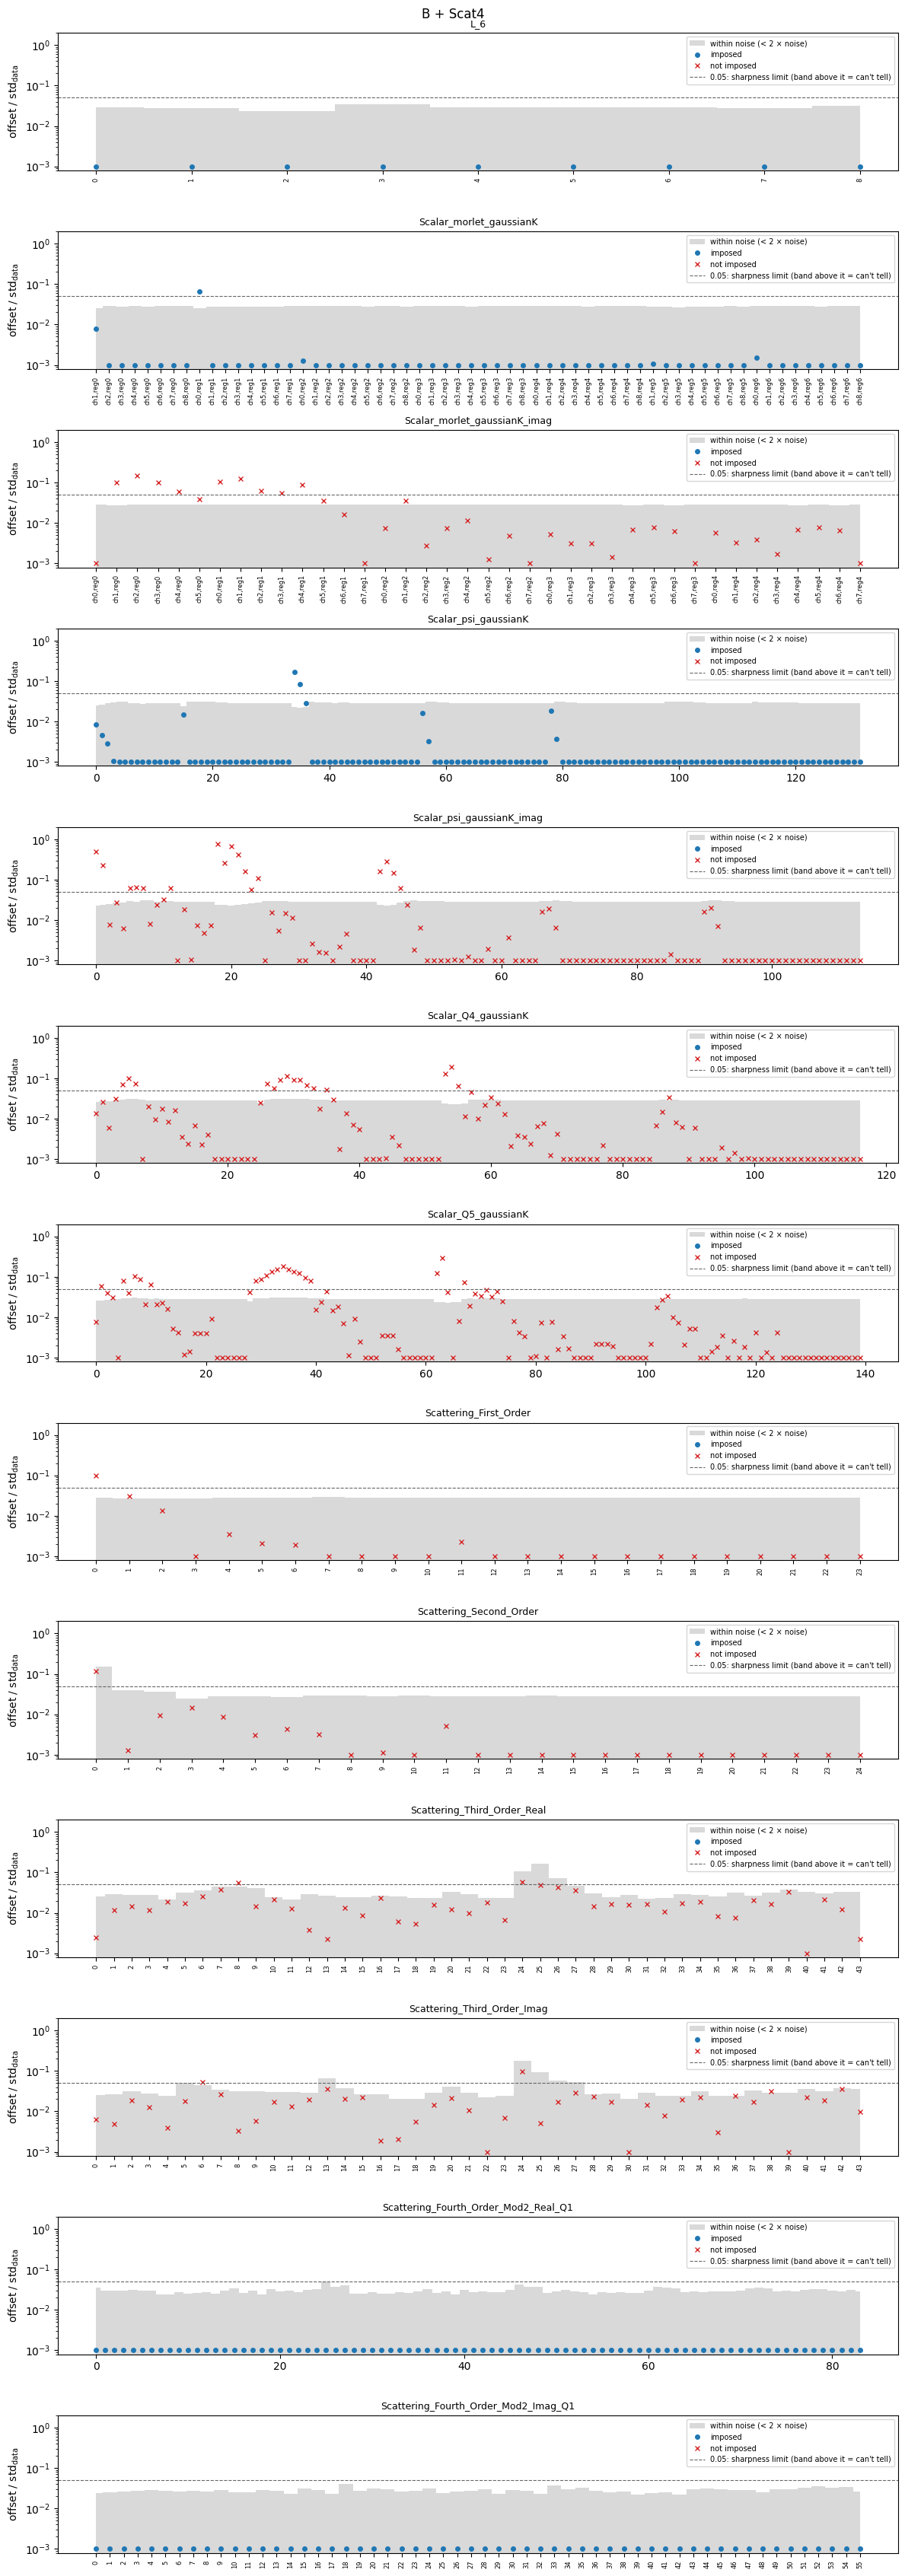

In [6]:
for group, res in results.items():
    for name, df in res.items():
        plot_strip(df).suptitle(name, y=1.0)

In [7]:
# Table per model and family. offset = |m - mhat| / std_data. Verdict per statistic:
#   matched = within 2 x noise AND 2 x noise < 0.05 (sharp);  can't tell = within noise but noise too large;
#   miss = outside noise.  rel_mean = (mhat - m)/|m| in %, only where |m| >= 0.5 std_data (else blank).
import pandas as pd
pd.set_option('display.float_format', '{:.3g}'.format)
for group, res in results.items():
    for name, df in res.items():
        print(f'\n== {name}')
        g = df.groupby(['imposed', 'family'])
        display(pd.DataFrame({
            'n':                   g.size(),
            'matched %':           100 * g['verdict'].apply(lambda s: (s == 'matched').mean()),
            "can't tell %":        100 * g['verdict'].apply(lambda s: (s == 'unresolved').mean()),
            'miss %':              100 * g['verdict'].apply(lambda s: (s == 'miss').mean()),
            'offset median':       g['offset'].median(),
            'offset max':          g['offset'].max(),
            '|rel_mean| median %': 100 * g['rel_mean'].apply(lambda s: s.abs().median()),
            'rel_mean shown':      g['rel_mean'].count(),
        }))
        big = df[df.offset > 0.1].sort_values('offset', ascending=False)
        print(f'offset > 0.1 std_data: {len(big)} statistics (top 30)')
        display(big[['family', 'label', 'imposed', 'verdict', 'offset', 'noise', 'rel_mean']].head(30))


== full (Scat4)


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   117       77.8             0   
        Scalar_Q5_gaussianK                   140       78.6             0   
        Scalar_morlet_gaussianK_imag           38       65.8             0   
        Scalar_psi_gaussianK_imag             114       78.1             0   
        Scattering_First_Order                 24       79.2             0   
        Scattering_Second_Order                25         96             0   
        Scattering_Third_Order_Imag            44       77.3          15.9   
        Scattering_Third_Order_Real            44       86.4          11.4   
True    L_6                                     9        100             0   
        Scalar_morlet_gaussianK                44       95.5             0   
        Scalar_psi_gaussianK                  107       90.7             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56        100             0   
        Scattering_Fourth_Order_Mod2_Real_Q1   84        100             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     22.2        0.00281   
        Scalar_Q5_gaussianK                     21.4        0.00443   
        Scalar_morlet_gaussianK_imag            34.2         0.0159   
        Scalar_psi_gaussianK_imag               21.9        0.00136   
        Scattering_First_Order                  20.8        0.00209   
        Scattering_Second_Order                    4        0.00218   
        Scattering_Third_Order_Imag             6.82         0.0103   
        Scattering_Third_Order_Real             2.27         0.0104   
True    L_6                                        0       8.93e-07   
        Scalar_morlet_gaussianK                 4.55       7.88e-07   
        Scalar_psi_gaussianK                    9.35       2.44e-06   
        Scattering_Fourth_Order_Mod2_Imag_Q1       0       1.17e-06   
        Scattering_Fourth_Order_Mod2_Real_Q1       0       6.14e-07   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                        0.226                0.494   
        Scalar_Q5_gaussianK                        0.329                0.527   
        Scalar_morlet_gaussianK_imag               0.144                 1.79   
        Scalar_psi_gaussianK_imag                  0.569                0.728   
        Scattering_First_Order                     0.124                0.157   
        Scattering_Second_Order                   0.0418               0.0452   
        Scattering_Third_Order_Imag               0.0585                  NaN   
        Scattering_Third_Order_Real               0.0777                  NaN   
True    L_6                                     6.92e-06                  NaN   
        Scalar_morlet_gaussianK                    0.212             0.000125   
        Scalar_psi_gaussianK                        1.72             0.000459   
        Scattering_Fourth_Order_Mod2_Imag_Q1    8.28e-06                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1    0.000192                  NaN   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               82  
        Scalar_Q5_gaussianK                               98  
        Scalar_morlet_gaussianK_imag                      22  
        Scalar_psi_gaussianK_imag                         65  
        Scattering_First_Order                            24  
        Scattering_Second_Order                           14  
        Scattering_Third_Order_Imag                        0  
        Scattering_Third_Ord

offset > 0.1 std_data: 58 statistics (top 30)


,family,label,imposed,verdict,offset,noise,rel_mean
9,Scalar_psi_gaussianK,"Scalar_psi_gaussianK[ch0,reg0]",True,miss,1.72,0.0123,-0.249
10,Scalar_psi_gaussianK,"Scalar_psi_gaussianK[ch1,reg0]",True,miss,0.683,0.0115,-0.154
494,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch1,reg1]",False,miss,0.569,0.0121,-0.0975
28,Scalar_psi_gaussianK,"Scalar_psi_gaussianK[ch0,reg1]",True,miss,0.553,0.0118,0.345
475,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch0,reg0]",False,miss,0.53,0.0117,-0.141
11,Scalar_psi_gaussianK,"Scalar_psi_gaussianK[ch2,reg0]",True,miss,0.416,0.0121,-0.0966
477,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch2,reg0]",False,miss,0.4,0.0127,-0.0693
517,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch0,reg2]",False,miss,0.339,0.0124,0.306
476,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch1,reg0]",False,miss,0.337,0.0137,0.124
769,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg2]",False,miss,0.329,0.0123,0.111



== B (bicw_allmass)


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   117       82.1             0   
        Scalar_Q5_gaussianK                   140       77.9             0   
        Scalar_morlet_gaussianK_imag           38       68.4             0   
        Scalar_psi_gaussianK_imag             114       84.2             0   
        Scattering_First_Order                 24       95.8             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56       62.5          1.79   
        Scattering_Fourth_Order_Mod2_Real_Q1   84       84.5          4.76   
        Scattering_Second_Order                25         80             0   
        Scattering_Third_Order_Imag            44       97.7             0   
        Scattering_Third_Order_Real            44       95.5             0   
True    L_6                                     9        100             0   
        Scalar_morlet_gaussianK                60       98.3             0   
        Scalar_psi_gaussianK                  132       97.7             0   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     17.9        0.00229   
        Scalar_Q5_gaussianK                     22.1        0.00277   
        Scalar_morlet_gaussianK_imag            31.6        0.00714   
        Scalar_psi_gaussianK_imag               15.8       0.000548   
        Scattering_First_Order                  4.17       0.000302   
        Scattering_Fourth_Order_Mod2_Imag_Q1    35.7         0.0167   
        Scattering_Fourth_Order_Mod2_Real_Q1    10.7         0.0102   
        Scattering_Second_Order                   20       0.000529   
        Scattering_Third_Order_Imag             2.27        0.00824   
        Scattering_Third_Order_Real             4.55         0.0106   
True    L_6                                        0       8.95e-07   
        Scalar_morlet_gaussianK                 1.67       7.98e-07   
        Scalar_psi_gaussianK                    2.27       2.39e-06   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                        0.191                0.394   
        Scalar_Q5_gaussianK                        0.295                0.457   
        Scalar_morlet_gaussianK_imag               0.148                 1.34   
        Scalar_psi_gaussianK_imag                   0.78                0.179   
        Scattering_First_Order                    0.0853               0.0203   
        Scattering_Fourth_Order_Mod2_Imag_Q1      0.0539                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1      0.0427                  NaN   
        Scattering_Second_Order                   0.0343               0.0203   
        Scattering_Third_Order_Imag               0.0272                  NaN   
        Scattering_Third_Order_Real               0.0292                  NaN   
True    L_6                                     6.78e-06                  NaN   
        Scalar_morlet_gaussianK                   0.0664             0.000109   
        Scalar_psi_gaussianK                       0.168             0.000296   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               82  
        Scalar_Q5_gaussianK                               98  
        Scalar_morlet_gaussianK_imag                      22  
        Scalar_psi_gaussianK_imag                         65  
        Scattering_First_Order                            24  
        Scattering_Fourth_Order_Mod2_Imag_Q1               0  
        Scattering_Fourth_Order_Mod2_Real_Q1               0  
        Scattering_Second_Or

... (6 outputs left out)


== B + Scat4


n  matched %  can't tell %  \
imposed family                                                               
False   Scalar_Q4_gaussianK                   117       82.1             0   
        Scalar_Q5_gaussianK                   140       77.9             0   
        Scalar_morlet_gaussianK_imag           38       68.4             0   
        Scalar_psi_gaussianK_imag             114       83.3             0   
        Scattering_First_Order                 24       91.7             0   
        Scattering_Second_Order                25         96             4   
        Scattering_Third_Order_Imag            44       84.1          11.4   
        Scattering_Third_Order_Real            44       90.9          6.82   
True    L_6                                     9        100             0   
        Scalar_morlet_gaussianK                60       98.3             0   
        Scalar_psi_gaussianK                  132       97.7             0   
        Scattering_Fourth_Order_Mod2_Imag_Q1   56        100             0   
        Scattering_Fourth_Order_Mod2_Real_Q1   84       98.8          1.19   

                                              miss %  offset median  \
imposed family                                                        
False   Scalar_Q4_gaussianK                     17.9        0.00193   
        Scalar_Q5_gaussianK                     22.1        0.00256   
        Scalar_morlet_gaussianK_imag            31.6        0.00678   
        Scalar_psi_gaussianK_imag               16.7       0.000469   
        Scattering_First_Order                  8.33       0.000208   
        Scattering_Second_Order                    0       0.000499   
        Scattering_Third_Order_Imag             4.55         0.0169   
        Scattering_Third_Order_Real             2.27         0.0152   
True    L_6                                        0       8.78e-07   
        Scalar_morlet_gaussianK                 1.67       8.16e-07   
        Scalar_psi_gaussianK                    2.27       2.37e-06   
        Scattering_Fourth_Order_Mod2_Imag_Q1       0       1.15e-06   
        Scattering_Fourth_Order_Mod2_Real_Q1       0       5.69e-07   

                                              offset max  |rel_mean| median %  \
imposed family                                                                  
False   Scalar_Q4_gaussianK                        0.192                0.331   
        Scalar_Q5_gaussianK                        0.297                0.398   
        Scalar_morlet_gaussianK_imag               0.147                 1.29   
        Scalar_psi_gaussianK_imag                  0.773                0.201   
        Scattering_First_Order                    0.0978               0.0173   
        Scattering_Second_Order                    0.115                0.023   
        Scattering_Third_Order_Imag               0.0993                  NaN   
        Scattering_Third_Order_Real               0.0572                  NaN   
True    L_6                                     6.97e-06                  NaN   
        Scalar_morlet_gaussianK                   0.0668             9.74e-05   
        Scalar_psi_gaussianK                       0.169             0.000296   
        Scattering_Fourth_Order_Mod2_Imag_Q1    8.14e-06                  NaN   
        Scattering_Fourth_Order_Mod2_Real_Q1    0.000168                  NaN   

                                              rel_mean shown  
imposed family                                                
False   Scalar_Q4_gaussianK                               82  
        Scalar_Q5_gaussianK                               98  
        Scalar_morlet_gaussianK_imag                      22  
        Scalar_psi_gaussianK_imag                         65  
        Scattering_First_Order                            24  
        Scattering_Second_Order                           14  
        Scattering_Third_Order_Imag                        0  
        Scattering_Third_Ord

offset > 0.1 std_data: 30 statistics (top 30)


,family,label,imposed,verdict,offset,noise,rel_mean
534,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch0,reg1]",False,miss,0.773,0.0118,0.164
536,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch2,reg1]",False,miss,0.681,0.0116,0.243
516,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch0,reg0]",False,miss,0.507,0.0116,-0.135
537,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch3,reg1]",False,miss,0.41,0.012,0.149
810,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch1,reg2]",False,miss,0.297,0.0117,0.0999
559,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch1,reg2]",False,miss,0.278,0.0113,0.13
535,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch1,reg1]",False,miss,0.265,0.0121,-0.0453
517,Scalar_psi_gaussianK_imag,"Scalar_psi_gaussianK_imag[ch1,reg0]",False,miss,0.226,0.0119,-0.0832
684,Scalar_Q4_gaussianK,"Scalar_Q4_gaussianK[ch1,reg2]",False,miss,0.192,0.0115,0.064
781,Scalar_Q5_gaussianK,"Scalar_Q5_gaussianK[ch11,reg1]",False,miss,0.183,0.0152,-0.107


## Moment reproduction vs contribution to −log p, per category
The talk's energy table (same categories and layout), one block per model, with the moment reproduction added. Columns: scalar multiscale (marginals + scattering 1–2) · scalar Im (marginals of the imaginary parts) · order 3 Re / Im · order 4 Re / Im · confinement ($L_6$). Only the families the model **imposes** count (they are the ones with a $\Theta$).
Rows: number of moments · **moments matched** (% of those statistics with a 'matched' verdict) · **mean offset** (mean over those statistics, in data std) · mean and std over the data signals of the category's contribution to $-\log p$ (sum of its families' contributions, std of the sum; variance = std²; the mean is a level only).
−log p comes from `turbulence/figures/data/logp_C_<label>_lam*.npz` (the L$_6<0$ file when there is one) or `jets/figures/logp_jets/logp_jets.npz` (printed below); a model with no such file shows '—' for $-\log p$. Seed = that of the moment-reproduction run, so no ± over seeds. Saved in `moment_reproduction/figures/`.

In [ ]:
from moment_reproduction import load_logp_contributions, plot_moment_vs_logp
from codes import talk_figures as tf
tf.set_output(ROOT / 'moment_reproduction' / 'figures')
for group, res in results.items():
    logp = {}
    for name in res:
        root, label = GROUPS[group][name]
        logp[name], src = load_logp_contributions(label, root)
        print(f'{name}: ' + (src if logp[name] is not None else f'NO log p ({src})'))
    plot_moment_vs_logp(res, logp, 'moment_vs_logp_' + group.split(' ')[0])